<a href="https://colab.research.google.com/github/bek180/computer-vision-projects/blob/main/%22app%20Student_Activity_Recognition_i%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Computer_Vision_Project"

DATASET_PATH = os.path.join(PROJECT_PATH, "dataset")
MODELS_PATH = os.path.join(PROJECT_PATH, "models")
RESULTS_PATH = os.path.join(PROJECT_PATH, "results")

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20

print("Dataset:", DATASET_PATH)
print("Models:", MODELS_PATH)
print("Results:", RESULTS_PATH)

Dataset: /content/drive/MyDrive/Computer_Vision_Project/dataset
Models: /content/drive/MyDrive/Computer_Vision_Project/models
Results: /content/drive/MyDrive/Computer_Vision_Project/results


In [ ]:
os.makedirs(DATASET_PATH, exist_ok=True)
os.makedirs(MODELS_PATH, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

classes = [
    "reading",
    "writing",
    "using_laptop",
    "using_phone",
    "idle"
]

for class_name in classes:
    os.makedirs(
        os.path.join(DATASET_PATH, class_name),
        exist_ok=True
    )

print("Folders created.")

Folders created.


In [ ]:
for class_name in classes:
    folder = os.path.join(DATASET_PATH, class_name)

    images = [
        file for file in os.listdir(folder)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{class_name}: {len(images)} images")

reading: 154 images
writing: 91 images
using_laptop: 122 images
using_phone: 120 images
idle: 130 images


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

##CNN

In [ ]:
#делим датасет
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

validation_test_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

Found 617 files belonging to 5 classes.
Using 432 files for training.
Found 617 files belonging to 5 classes.
Using 185 files for validation.


In [ ]:
validation_batches = tf.data.experimental.cardinality(
    validation_test_dataset
)

test_dataset = validation_test_dataset.take(
    validation_batches // 2
)

validation_dataset = validation_test_dataset.skip(
    validation_batches // 2
)

In [ ]:
class_names = train_dataset.class_names

print(class_names)

['idle', 'reading', 'using_laptop', 'using_phone', 'writing']


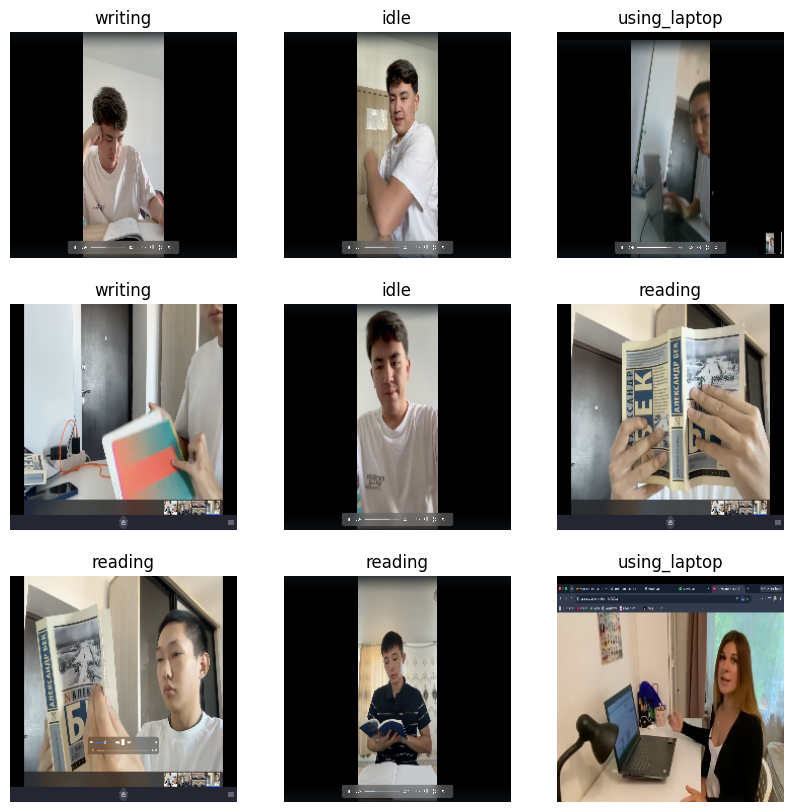

In [ ]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.show()

In [ ]:
normalization_layer = layers.Rescaling(1./255)

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

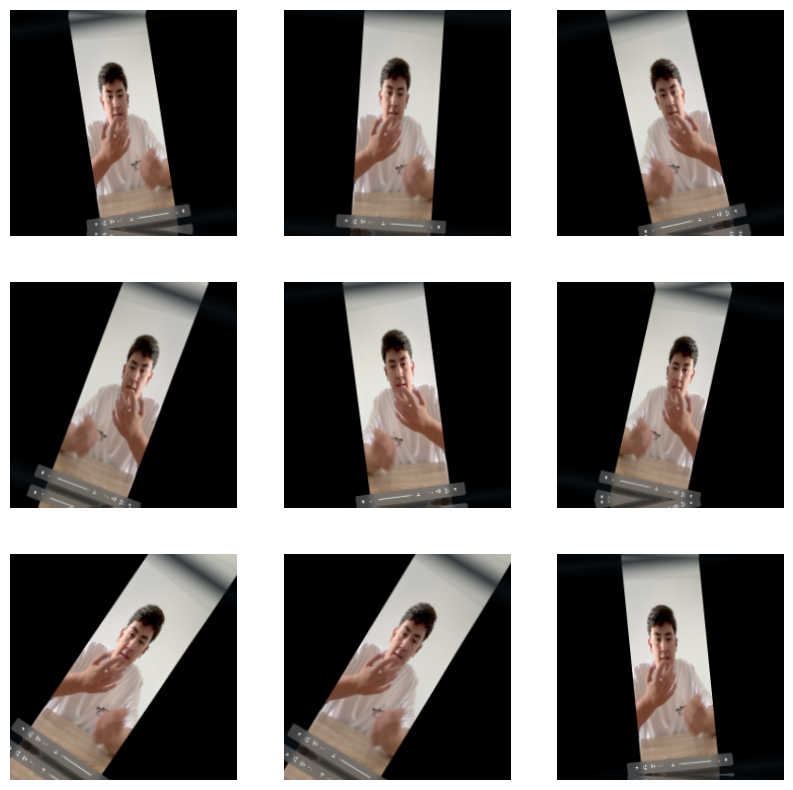

In [ ]:
for images, labels in train_dataset.take(1):

    image = images[0]

    plt.figure(figsize=(10, 10))

    for i in range(9):

        augmented_image = data_augmentation(
            tf.expand_dims(image, 0)
        )

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            augmented_image[0].numpy().astype("uint8")
        )

        plt.axis("off")

plt.show()

In [ ]:
num_classes = len(class_names)

baseline_model = keras.Sequential([

    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(
        num_classes,
        activation="softmax"
    )
])

In [ ]:
baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
baseline_history = baseline_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 305s 22s/step - accuracy: 0.2130 - loss: 1.6090 - val_accuracy: 0.2360 - val_loss: 1.6011
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 99s 7s/step - accuracy: 0.2616 - loss: 1.6021 - val_accuracy: 0.3258 - val_loss: 1.5853
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 139s 7s/step - accuracy: 0.2500 - loss: 1.5985 - val_accuracy: 0.2135 - val_loss: 1.5907
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 146s 7s/step - accuracy: 0.2384 - loss: 1.5925 - val_accuracy: 0.2135 - val_loss: 1.5773
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 99s 7s/step - accuracy: 0.2894 - loss: 1.5749 - val_accuracy: 0.2135 - val_loss: 1.5437
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 96s 7s/step - accuracy: 0.2546 - loss: 1.5639 - val_accuracy: 0.4382 - val_loss: 1.4700
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 101s 7s/step - accuracy: 0.3102 - loss: 1.5129 - val_accuracy: 0.3596 - val_loss: 1.4323
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 96s 7s/step - accuracy: 0.3032 - loss: 1.4811 - val_accuracy: 0.3371 - val_

In [ ]:
baseline_model.save(
    os.path.join(
        MODELS_PATH,
        "baseline_cnn.keras"
    )
)

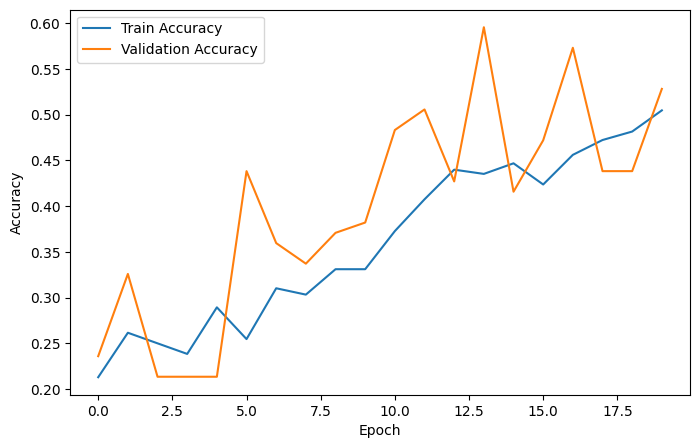

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    baseline_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

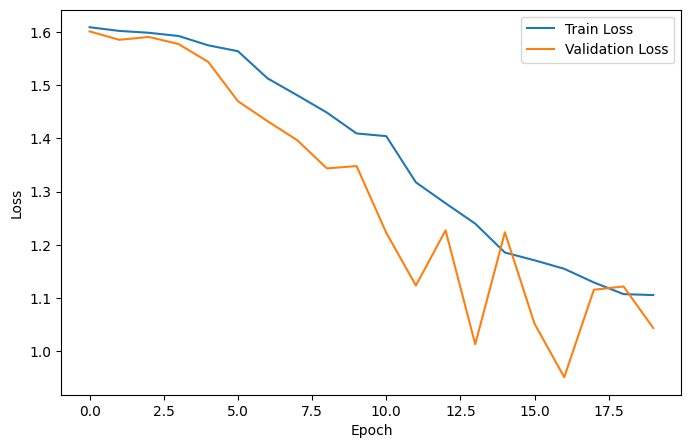

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    baseline_history.history["loss"],
    label="Train Loss"
)

plt.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

##MobileNetV2

In [ ]:
import tensorflow as tf
import numpy as np

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
base_model.trainable = False

In [ ]:
inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

improved_model = keras.Model(
    inputs,
    outputs
)

In [ ]:
improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
improved_history = improved_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 110s 8s/step - accuracy: 0.8542 - loss: 0.4490 - val_accuracy: 0.7753 - val_loss: 0.5525
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 104s 5s/step - accuracy: 0.8611 - loss: 0.4371 - val_accuracy: 0.8090 - val_loss: 0.4775
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 92s 6s/step - accuracy: 0.8889 - loss: 0.3839 - val_accuracy: 0.7753 - val_loss: 0.5217
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 68s 5s/step - accuracy: 0.8750 - loss: 0.3829 - val_accuracy: 0.7978 - val_loss: 0.4847
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 70s 5s/step - accuracy: 0.8750 - loss: 0.4093 - val_accuracy: 0.8090 - val_loss: 0.4989


In [ ]:
improved_model.save(
    os.path.join(
        MODELS_PATH,
        "mobilenetv2_model.keras"
    )
)

In [ ]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    test_dataset
)

print(
    "Baseline Accuracy:",
    baseline_accuracy
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 23s 7s/step - accuracy: 0.1562 - loss: 1.6084
Baseline Accuracy: 0.15625


In [ ]:
improved_loss, improved_accuracy = improved_model.evaluate(
    test_dataset
)

print(
    "Improved Accuracy:",
    improved_accuracy
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.7812 - loss: 0.5087
Improved Accuracy: 0.78125


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

In [ ]:
y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = improved_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_labels
    )

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

        idle       0.00      0.00      0.00        24
     reading       0.40      0.07      0.12        28
using_laptop       0.00      0.00      0.00        15
 using_phone       0.00      0.00      0.00        20
     writing       0.10      1.00      0.18         9

    accuracy                           0.11        96
   macro avg       0.10      0.21      0.06        96
weighted avg       0.13      0.11      0.05        96



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


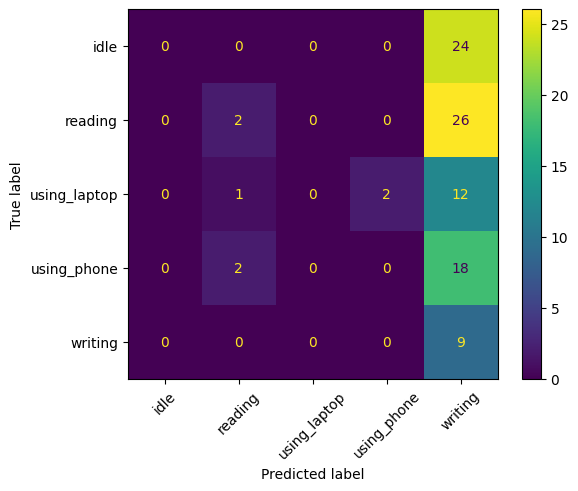

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=45
)

plt.show()

In [ ]:
print("Model comparison")

print(
    "Baseline CNN:",
    round(baseline_accuracy * 100, 2),
    "%"
)

print(
    "MobileNetV2:",
    round(improved_accuracy * 100, 2),
    "%"
)

Model comparison


NameError: name 'baseline_accuracy' is not defined

In [ ]:
img_path = "/content/drive/MyDrive/Computer_Vision_Project/test.jpg"

img = tf.keras.utils.load_img(
    img_path,
    target_size=IMAGE_SIZE
)

img_array = tf.keras.utils.img_to_array(img)

img_array = tf.expand_dims(
    img_array,
    0
)

predictions = improved_model.predict(
    img_array
)

score = predictions[0]

predicted_class = class_names[
    np.argmax(score)
]

confidence = 100 * np.max(score)

print(
    f"Prediction: {predicted_class}"
)

print(
    f"Confidence: {confidence:.2f}%"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
Prediction: writing
Confidence: 68.04%


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
